# Задание 3.4

**(Задача о таутохроне)** Найти кривую, по которой время скатывания материальной точки под действием силы тяжести до нижней точки не зависит от начального положения (изохронная кривая).

1) В ноутбуке (файл Jupyter Notebook) в разметке Markdown (LaTeX) привести подробное аналитическое решение (постановка задачи, вывод интегрального уравнения, решение);
2) Привести статическую картинку в формате png (pdf) решения задачи (код на Jupyter Notebook, который создаёт рисунок);
3) Используя инструментарий Jupyter Notebook, привести анимацию данного решения.

**Детализация задания.** *Цель:* исследовать и визуализировать таутохронную кривую (циклоиду), обеспечивающую постоянное время спуска.

- **Аналитическое решение:** составить интегральное уравнение для времени спуска; решить интегральное уравнение Абеля; получить параметрические уравнения циклоиды; доказать независимость времени спуска от начальной точки.
- **Статическая визуализация:** график циклоиды и её геометрическое построение; несколько траекторий с разных начальных высот; качение образующей окружности; сетка, подписи осей, легенда.
- **Анимация:** `FuncAnimation`; одновременное скатывание шариков с разных высот; геометрическое построение циклоиды; равенство времён спуска.

## Теория

**1. Постановка задачи.** Ось $y$ направлена вверх, нижняя точка кривой — начало координат. Точка без трения скатывается по кривой из состояния покоя с высоты $h$. Пусть $s(y)$ — длина дуги от нижней точки до уровня $y$, а $\phi(y)=\dfrac{ds}{dy}$ — неизвестная функция, задающая кривую. Из закона сохранения энергии скорость на высоте $y$ равна

$$
v=\left|\frac{ds}{dt}\right|=\sqrt{2g\,(h-y)} .
$$

**2. Интегральное уравнение для времени спуска.** Время спуска с высоты $h$:

$$
T(h)=\int_0^h\frac{ds}{v}=\frac{1}{\sqrt{2g}}\int_0^h\frac{\phi(y)\,dy}{\sqrt{h-y}} .
$$

Требование таутохронности $T(h)=T=\mathrm{const}$ для всех $h$ даёт **интегральное уравнение Абеля** относительно $\phi$:

$$
\boxed{\ \int_0^h\frac{\phi(y)\,dy}{\sqrt{h-y}}=\sqrt{2g}\,T\ }
$$

**3. Решение уравнения Абеля.** Общее уравнение $\displaystyle\int_0^h\frac{\phi(y)\,dy}{\sqrt{h-y}}=F(h)$ имеет решение

$$
\phi(y)=\frac1\pi\,\frac{d}{dy}\int_0^y\frac{F(h)\,dh}{\sqrt{y-h}} .
$$

Его можно получить преобразованием Лапласа: левая часть — свёртка $\phi * t^{-1/2}$, а $\mathcal L[t^{-1/2}]=\sqrt{\pi/p}$. Для $F\equiv\sqrt{2g}\,T$:

$$
\int_0^y\frac{\sqrt{2g}\,T\,dh}{\sqrt{y-h}}=2\sqrt{2g}\,T\sqrt y\quad\Longrightarrow\quad
\phi(y)=\frac{\sqrt{2g}\,T}{\pi\sqrt y}=\sqrt{\frac{D}{y}},\qquad D=\frac{2gT^2}{\pi^2}.
$$

Проверка подстановкой: $\displaystyle\int_0^h\frac{dy}{\sqrt{y(h-y)}}=\pi$, поэтому $\displaystyle\int_0^h\frac{\sqrt{D}\,dy}{\sqrt{y}\sqrt{h-y}}=\pi\sqrt D=\sqrt{2g}\,T$ — верно при любом $h$.

**4. Циклоида.** Так как $ds^2=dx^2+dy^2$, получаем $\phi^2=1+\left(\dfrac{dx}{dy}\right)^2=\dfrac Dy$, откуда

$$
\frac{dx}{dy}=\sqrt{\frac{D-y}{y}} .
$$

Подстановка $y=\dfrac D2(1-\cos\theta)$ даёт $dx=\sqrt{\dfrac{1+\cos\theta}{1-\cos\theta}}\cdot\dfrac D2\sin\theta\,d\theta=\dfrac D2(1+\cos\theta)\,d\theta$. С $R=\dfrac D2=\dfrac{gT^2}{\pi^2}$:

$$
\boxed{\ x=R\,(\theta+\sin\theta),\qquad y=R\,(1-\cos\theta),\qquad \theta\in[-\pi,\pi]\ }
$$

Это перевёрнутая **циклоида**. Её описывает точка окружности радиуса $R$, катящейся без скольжения по нижней стороне прямой $y=2R$: центр окружности $(R\theta,\,R)$, точка $=(R\theta+R\sin\theta,\ R-R\cos\theta)$. Время спуска $\ \boxed{T=\pi\sqrt{R/g}}$.

**5. Независимость времени спуска от начальной точки (прямое доказательство).** Для циклоиды $ds=2R\cos\frac\theta2\,d\theta$, так что $s=4R\sin\dfrac\theta2$ и $y=R(1-\cos\theta)=2R\sin^2\dfrac\theta2=\dfrac{s^2}{8R}$. Касательная составляющая силы тяжести на единицу массы равна

$$
\ddot s=-g\,\frac{dy}{ds}=-\frac{g}{4R}\,s ,
$$

то есть движение по дуге — **гармонические колебания** с частотой $\omega=\sqrt{g/(4R)}$, не зависящей от амплитуды. При старте из покоя $s(t)=s_0\cos\omega t$, и нижней точки ($s=0$) точка достигает при

$$
t=\frac{\pi}{2\omega}=\pi\sqrt{\frac Rg}\qquad\text{при любом } s_0 .
$$

Для сравнения: на окружности (обычный маятник) $\ddot s=-g\sin(s/\rho)$, сила нелинейна, и время спуска растёт с высотой.

**Что делаем в коде.** `sympy` проверяет ключевой интеграл $\int_0^h\frac{dy}{\sqrt{y(h-y)}}=\pi$. Движение по циклоиде считаем численно (`solve_ivp`) по общему уравнению движения по параметрической кривой $(x(\theta),y(\theta))$:

$$
\ddot\theta=-\frac{g\,y'+(x'x''+y'y'')\,\dot\theta^2}{x'^2+y'^2},
$$

и находим момент прихода в нижнюю точку для разных высот. Интеграл Абеля $T(h)$ считаем `scipy.integrate.quad` (с весом $y^{-1/2}(h-y)^{-1/2}$) для циклоиды и для окружности. Анимация показывает катящуюся окружность, рисующую циклоиду, и одновременный спуск шариков; она встроена через `to_jshtml()` (проигрыватель с паузой и шагом).

∫_0^h dy / √(y(h-y)) = pi  → T не зависит от h

Теория: T = π√(R/g) = 1.003033 с
θ0 =    20°,  h = 0.060 м:  t_спуска = 1.003033 с
θ0 =    60°,  h = 0.500 м:  t_спуска = 1.003033 с
θ0 =   100°,  h = 1.174 м:  t_спуска = 1.003033 с
θ0 =   140°,  h = 1.766 м:  t_спуска = 1.003033 с
θ0 =   170°,  h = 1.985 м:  t_спуска = 1.003033 с


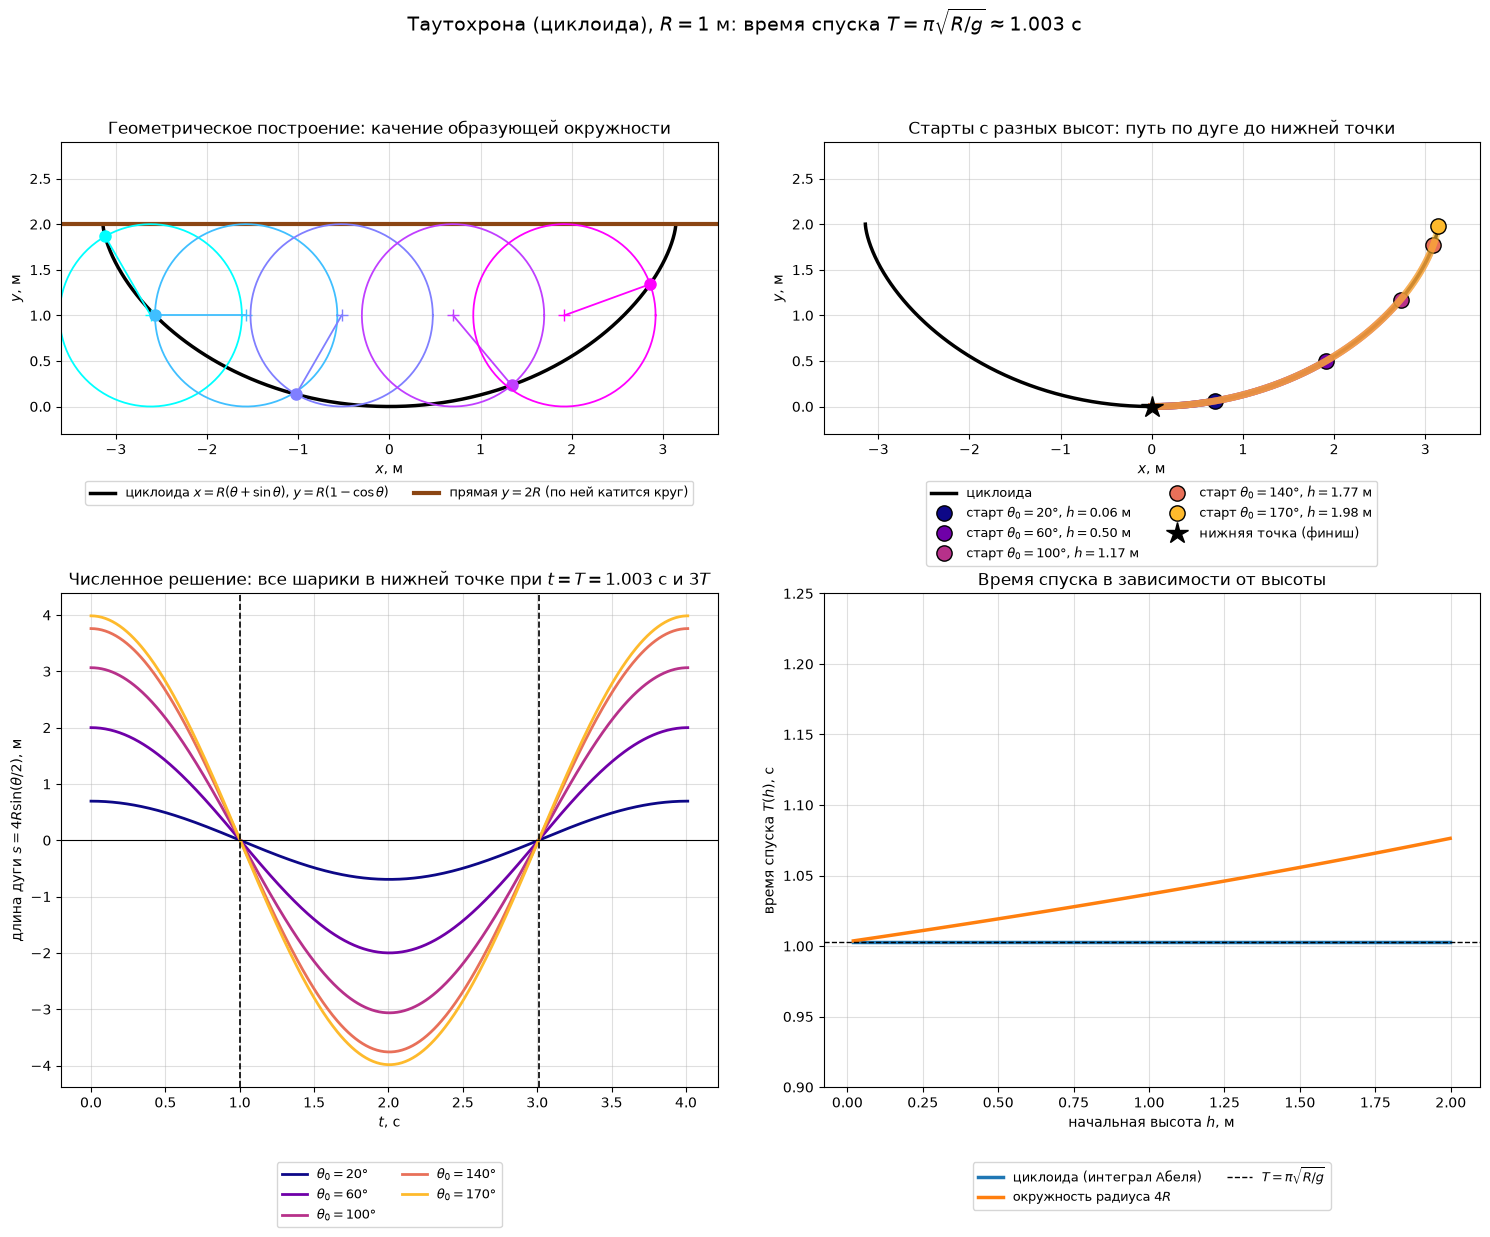

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp, quad
from IPython.display import HTML, display

g, R = 9.81, 1.0                       # радиус образующей окружности R
T_theor = np.pi*np.sqrt(R/g)           # теоретическое время спуска T = π√(R/g)
omega = np.sqrt(g/(4*R))               # частота колебаний по дуге

# ---------- Символьная проверка ключевого интеграла уравнения Абеля ----------
y_, h_ = sp.symbols("y h", positive=True)
I = sp.integrate(1/sp.sqrt(y_*(h_ - y_)), (y_, 0, h_))
print("∫_0^h dy / √(y(h-y)) =", sp.simplify(I), " → T не зависит от h")

# Циклоида и её производные по параметру θ
cx = lambda th: R*(th + np.sin(th))
cy = lambda th: R*(1 - np.cos(th))


def rhs(t, u):
    """Движение без трения по параметрической кривой: θ'' = -(g y' + (x'x'' + y'y'') θ'²)/(x'² + y'²)."""
    th, w = u
    x1, y1 = R*(1 + np.cos(th)), R*np.sin(th)          # x'(θ), y'(θ)
    x2, y2 = -R*np.sin(th), R*np.cos(th)               # x''(θ), y''(θ)
    return [w, -(g*y1 + (x1*x2 + y1*y2)*w**2)/(x1**2 + y1**2)]


def bottom(t, u):                                      # событие: пришли в нижнюю точку θ = 0
    return u[0]
bottom.terminal, bottom.direction = True, -1

# ---------- Численная проверка: время прихода в нижнюю точку с разных высот ----------
theta0s = np.radians([20, 60, 100, 140, 170])
print(f"\nТеория: T = π√(R/g) = {T_theor:.6f} с")
for th0 in theta0s:
    sol = solve_ivp(rhs, [0, 5], [th0, 0.0], events=bottom, rtol=1e-11, atol=1e-12)
    print(f"θ0 = {np.degrees(th0):5.0f}°,  h = {cy(th0):.3f} м:  t_спуска = {sol.t_events[0][0]:.6f} с")

# Время спуска по интегралу Абеля T(h) = (1/√2g) ∫ φ(y) dy/√(h-y) для циклоиды и для окружности радиуса 4R
rho_c = 4*R                                              # окружность с той же кривизной в нижней точке
def T_abel(h, kind):
    if kind == "cycloid":                               # φ(y) = √(2R/y)
        f = lambda y: np.sqrt(2*R)
    else:                                               # окружность: φ(y) = ρ/√(y(2ρ - y))
        f = lambda y: rho_c/np.sqrt(2*rho_c - y)
    # вес y^{-1/2}(h-y)^{-1/2} учитываем точно (weight='alg') — особенности на концах интегрируемы
    val, _ = quad(f, 0, h, weight="alg", wvar=(-0.5, -0.5))
    return val/np.sqrt(2*g)

# ---------- Статический рисунок ----------
fig, axs = plt.subplots(2, 2, figsize=(15, 12.5))
th = np.linspace(-np.pi, np.pi, 600)

# (а) геометрическое построение: окружность катится по нижней стороне прямой y = 2R
ax = axs[0, 0]
ax.plot(cx(th), cy(th), "k-", lw=2.5, label="циклоида $x=R(\\theta+\\sin\\theta)$, $y=R(1-\\cos\\theta)$")
ax.axhline(2*R, color="saddlebrown", lw=3, label="прямая $y=2R$ (по ней катится круг)")
phi = np.linspace(0, 2*np.pi, 200)
for t_k, col in zip(np.radians([-150, -90, -30, 40, 110]), plt.cm.cool(np.linspace(0, 1, 5))):
    xc, yc = R*t_k, R                                   # центр окружности
    px, py = cx(t_k), cy(t_k)                           # образующая точка
    ax.plot(xc + R*np.cos(phi), yc + R*np.sin(phi), color=col, lw=1.3)
    ax.plot([xc, px], [yc, py], color=col, lw=1.3)
    ax.plot(px, py, "o", color=col, ms=8)
    ax.plot(xc, yc, "+", color=col, ms=8)
ax.set(title="Геометрическое построение: качение образующей окружности", xlim=(-3.6, 3.6), ylim=(-0.3, 2.9))

# (б) стартовые положения с разных высот
ax = axs[0, 1]
ax.plot(cx(th), cy(th), "k-", lw=2.5, label="циклоида")
cols = plt.cm.plasma(np.linspace(0, 0.85, len(theta0s)))
for th0, col in zip(theta0s, cols):
    arc = np.linspace(0, th0, 200)
    ax.plot(cx(arc), cy(arc), color=col, lw=5, alpha=0.6)
    ax.plot(cx(th0), cy(th0), "o", color=col, ms=11, mec="k", label=f"старт $\\theta_0={np.degrees(th0):.0f}°$, $h={cy(th0):.2f}$ м")
ax.plot(0, 0, "k*", ms=16, label="нижняя точка (финиш)")
ax.set(title="Старты с разных высот: путь по дуге до нижней точки", xlim=(-3.6, 3.6), ylim=(-0.3, 2.9))

# (в) s(t) для разных стартов: все кривые проходят через s = 0 в момент T
ax = axs[1, 0]
t = np.linspace(0, 4*T_theor, 500)
for th0, col in zip(theta0s, cols):
    sol = solve_ivp(rhs, [0, t[-1]], [th0, 0.0], t_eval=t, rtol=1e-10, atol=1e-12)
    ax.plot(t, 4*R*np.sin(sol.y[0]/2), color=col, lw=2, label=f"$\\theta_0={np.degrees(th0):.0f}°$")
for k in (1, 3):
    ax.axvline(k*T_theor, color="k", ls="--", lw=1.2)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="$t$, с", ylabel="длина дуги $s=4R\\sin(\\theta/2)$, м",
       title=f"Численное решение: все шарики в нижней точке при $t=T={T_theor:.3f}$ с и $3T$")

# (г) время спуска T(h): циклоида (const) против окружности
ax = axs[1, 1]
hs = np.linspace(0.02, 2*R*0.999, 60)
ax.plot(hs, [T_abel(h, "cycloid") for h in hs], "-", color="tab:blue", lw=2.5, label="циклоида (интеграл Абеля)")
ax.plot(hs, [T_abel(h, "circle") for h in hs], "-", color="tab:orange", lw=2.5, label=f"окружность радиуса $4R$")
ax.axhline(T_theor, color="k", ls="--", lw=1, label=r"$T=\pi\sqrt{R/g}$")
ax.set(xlabel="начальная высота $h$, м", ylabel="время спуска $T(h)$, с", title="Время спуска в зависимости от высоты",
       ylim=(0.9, 1.25))

for ax in axs.flat:
    ax.grid(alpha=0.4)
    ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)   # легенда под графиком
for ax in axs[0]:
    ax.set(xlabel="$x$, м", ylabel="$y$, м", aspect="equal")
fig.suptitle(f"Таутохрона (циклоида), $R={R:g}$ м: время спуска $T=\\pi\\sqrt{{R/g}}\\approx{T_theor:.3f}$ с", fontsize=14)
fig.tight_layout()
fig.savefig("3.4.png", dpi=150, bbox_inches="tight")        # сохраняем статическую картинку
plt.show()

# ---------- Анимация ----------
n_frames = 120
t_fr = np.linspace(0, 4*T_theor, n_frames)               # один полный период колебаний
starts = np.radians([30, 70, 110, 150])
cols = plt.cm.plasma(np.linspace(0, 0.85, len(starts)))
TH = np.array([solve_ivp(rhs, [0, t_fr[-1]], [th0, 0.0], t_eval=t_fr, rtol=1e-10, atol=1e-12).y[0] for th0 in starts])
S = 4*R*np.sin(TH/2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.6), dpi=65, gridspec_kw=dict(width_ratios=[1.45, 1]))
# левая панель: катящаяся окружность рисует циклоиду, по циклоиде скатываются шарики
ax1.axhline(2*R, color="saddlebrown", lw=3)
ax1.plot(cx(th), cy(th), color="lightgray", lw=6, zorder=0)
drawn, = ax1.plot([], [], "k-", lw=2, label="циклоида, рисуемая окружностью")
circ, = ax1.plot([], [], color="tab:cyan", lw=1.5)
spoke, = ax1.plot([], [], color="tab:cyan", lw=1.5)
gen_pt, = ax1.plot([], [], "o", color="tab:cyan", ms=7, label="образующая точка")
balls = [ax1.plot([], [], "o", color=c, mec="k", ms=13, zorder=5)[0] for c in cols]
for th0, c in zip(starts, cols):
    ax1.plot(cx(th0), cy(th0), "x", color=c, ms=9, mew=2)
ax1.plot(0, 0, "k*", ms=14)
info = ax1.set_title(" \n ", family="monospace", fontsize=10)    # параметры движения — в заголовке, над графиком
ax1.set(xlim=(-3.4, 3.4), ylim=(-0.3, 2.4), aspect="equal", xlabel="$x$, м", ylabel="$y$, м")
ax1.grid(alpha=0.3); ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9, ncol=2)

# правая панель: s(t) рисуется в реальном времени, отметки t = T и 3T
lines = [ax2.plot([], [], color=c, lw=2, label=f"$\\theta_0={np.degrees(t0):.0f}°$")[0] for t0, c in zip(starts, cols)]
for k in (1, 3):
    ax2.axvline(k*T_theor, color="k", ls="--", lw=1)
ax2.axhline(0, color="k", lw=0.8)
ax2.set(xlim=(0, t_fr[-1]), ylim=(-4.2*R, 4.2*R), xlabel="$t$, с", ylabel="$s(t)$, м",
        title="Длина дуги до нижней точки")
ax2.grid(alpha=0.3); ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=9, ncol=4)
th_draw = np.linspace(-np.pi, np.pi, n_frames)            # параметр катящейся окружности


def update(i):
    t = t_fr[i]
    # геометрическое построение: окружность с центром (Rθ, R) касается прямой y = 2R
    tk = th_draw[i]
    xc = R*tk
    circ.set_data(xc + R*np.cos(phi), R + R*np.sin(phi))
    spoke.set_data([xc, cx(tk)], [R, cy(tk)])
    gen_pt.set_data([cx(tk)], [cy(tk)])
    drawn.set_data(cx(th_draw[:i+1]), cy(th_draw[:i+1]))
    # шарики на циклоиде
    for b, thb in zip(balls, TH[:, i]):
        b.set_data([cx(thb)], [cy(thb)])
    for ln, s in zip(lines, S):
        ln.set_data(t_fr[:i+1], s[:i+1])
    # равенство времён спуска: все шарики одновременно внизу при t = T и t = 3T
    dt = t_fr[1] - t_fr[0]
    near = np.min(np.abs(t - np.array([1, 3])*T_theor)) < 1.5*dt     # кадры рядом с t = T, 3T
    msg = "все шарики внизу одновременно!" if near else ""
    info.set_text(f"t = {t:5.3f} с   t/T = {t/T_theor:4.2f}   T = π√(R/g) = {T_theor:.3f} с   max|s| = {np.max(np.abs(S[:, i])):4.2f} м\n{msg}")
    return [drawn, circ, spoke, gen_pt, info, *balls, *lines]


anim = FuncAnimation(fig, update, frames=n_frames, interval=50)
fig.tight_layout()
plt.close(fig)
display(HTML(anim.to_jshtml(default_mode="loop")))   # проигрыватель: пуск/пауза, шаг, скорость